In [1]:
# ]add SolidStateDetectors@0.10.28


In [2]:

# ]st SolidStateDetectors

In [3]:
using Revise

@info "Loading packages"
using Unitful
using DelimitedFiles
using COSIDetectors
using ProgressMeter
using TypedTables

using ParallelProcessingTools
using SolidStateDetectors, LegendHDF5IO, Logging
using DSP

dt = 1u"ns"
fast_filt = COSIDetectors.fast_shaper_filter(dt)
slow_filt = COSIDetectors.slow_shaper_filter(dt)
;

[ Info: Loading packages


In [4]:
using CairoMakie

In [5]:
@info "Reading in the electric fields of the test detector"
@time sim = ssd_read("/Users/Sophie/Desktop/COSI/simulations/COSI_SSD/lbl_HP41520-1.h5", Simulation)
T = SolidStateDetectors.get_precision_type(sim)
ismissing(sim.electric_field) && calculate_electric_field!(sim)

function scale_to_temperature(cdm::ADL2016ChargeDriftModel{T,M,N}, Temp::SolidStateDetectors.RealQuantity) where {T,M,N}
    
    # scale electron parameters
    μe::T = cdm.electrons.mu0 * (Temp / 77u"K") ^ -1.68
    βe::T = cdm.electrons.beta
    Ee::T = cdm.electrons.E0 * sqrt(tanh(200u"K" / (2*Temp)) / tanh(200u"K" / (2 * 77u"K"))) * cdm.electrons.mu0 / μe
    μn::T = μe / cdm.electrons.mu0 * cdm.electrons.mun
    electrons = SolidStateDetectors.VelocityParameters{T}(μe, βe, Ee, μn)
    
    # scale hole parameters (take <100> values and assume no anisotropy for now)
    μh::T = cdm.holes.axis100.mu0 * (Temp / 77u"K") ^ -2.40
    βh::T = cdm.holes.axis100.beta
    Eh::T = cdm.holes.axis100.E0 * sqrt(tanh(200u"K" / (2*Temp)) / tanh(200u"K" / (2 * 77u"K"))) * cdm.holes.axis100.mu0 / μh
    h100 = SolidStateDetectors.VelocityParameters{T}(μh, βh, Eh, zero(T))
    μh = cdm.holes.axis111.mu0 * (Temp / 77u"K") ^ -2.40
    βh = cdm.holes.axis111.beta
    Eh = cdm.holes.axis111.E0 * sqrt(tanh(200u"K" / (2*Temp)) / tanh(200u"K" / (2 * 77u"K"))) * cdm.holes.axis111.mu0 / μh
    h111 = SolidStateDetectors.VelocityParameters{T}(μh, βh, Eh, zero(T))
    holes = SolidStateDetectors.CarrierParameters(h100, h111)
    
    ADL2016ChargeDriftModel{T,M,N,typeof(cdm.temperaturemodel)}(electrons, holes, cdm.crystal_orientation, cdm.γ, cdm.parameters, cdm.temperaturemodel) 
end  


[ Info: Reading in the electric fields of the test detector


 44.613941 seconds (37.25 M allocations: 70.234 GiB, 6.48% gc time, 55.88% compilation time: <1% of which was recompilation)


scale_to_temperature (generic function with 1 method)

In [6]:
@info "Define function for adding noise"
# Simulate julia pulses in preamps, start with current and simulate just the charge-sensitive preamplifier part
# amplscale = 5.42623
noise = "100u" # "250u" # 2.955u"keV"
noise_corr_t = "500p"
strip_capacitance = "15p" # "15p" #"15p"
t_ngspice = "500n"
n_strips = 37 
@info "Simulating noise with an amplitude of $(noise), with an inter-strip capacitance of $(strip_capacitance)"

function create_netlist(evt::Event, n_strips = n_strips)
    return join((
    "* multi_asic_channel",
    (
    begin
    pad = 100
    wf = evt.waveforms[i].signal * (i <= n_strips ? -1 : 1)
    charge = deepcopy(wf[vcat(fill(1,pad), 1:end, fill(end,pad))])
    time = range(zero(dt), length = length(charge), step = dt)
    current = COSIDetectors.gradient(charge, time)
    """
    XC$(i) input$(i) p$(i) PREAMP
    AI$(i) %i(raw$(i)) src$(i)
    .model src$(i) pwlts(x_array=[$(join(float.(Unitful.ustrip.(u"s", time)), " "))] y_array=[$(join(float.(Unitful.ustrip.(u"A", current)), " "))])   
    * V$(i) input$(i) raw$(i) DC 0 TRNOISE($(noise) $(noise_corr_t) 0 0) 
    V$(i) input$(i) raw$(i) 0
    C$(i) raw$(i) 0 6p
    """
    end
    for i in 1:2*n_strips
    )...,
    # Define capacitances between the strips
    (
        "C$(i)to$(i+1) raw$(i) raw$(i+1) $(strip_capacitance)"
        for i in 1:2*n_strips-1 if i != n_strips
    )...,
    COSIDetectors.PREAMP_NETLIST,
    """
    .tran 1n $(t_ngspice)

    .control
        set noopinfo
        set nolegend
        set nosort
        set noinit
        run
        set width = 100000
        set numdgt = 9
        set wr_singlescale
        set nobreak
        set nopage
        print $(join(("v(p$(i))" for i in 1:2*n_strips), " "))
    .endc

    .end
    """), "\n")
end

    
function apply_electronics(evt::Event; n_samples = 5000, fast_threshold = 30.0)
    
    ngspice_warnings = IOBuffer()
    
    raw_output = try
        read(pipeline(`ngspice -b`, stdin = IOBuffer(create_netlist(evt)), stderr = ngspice_warnings), String)
    catch e
        write(stderr, take!(ngspice_warnings))
        rethrow(e)
    end

    # Filter only the lines that look like actual data (start with index)
    data_lines = split(raw_output, '\n')
    filter!(line -> startswith(line, r"^\s*\d"), data_lines)

    # Parse each line into a tuple of Float64
    sim_data = Matrix{Float64}(undef, length(data_lines), 2*n_strips+1)
    for i in eachindex(data_lines)
        @assert length(split(strip(data_lines[i]))) >= 2*n_strips+2 string(data_lines[i])
        sim_data[i,:] .= parse.(Float64, view(split(strip(data_lines[i])),2:2*n_strips+2))
    end

    idx = Array{Int}(undef, n_samples)

    j = 0
    for i in Base.OneTo(size(sim_data,1))
        s = sim_data[i,1]
        if s >= j * 1e-9
            idx[j+1] = i
            j += 1
        end
        if j >= length(idx) break end
    end

    sampled = view(sim_data, idx[min.(1:n_samples,j)], 1:size(sim_data,2));
    t = max.((1:n_samples).* dt, sampled[:,1] * dt)
    sampled_HV = sampled[:,2:n_strips+1]
    sampled_LV = sampled[:,n_strips+2:2*n_strips+1]
    
    return t, sampled
end

[ Info: Define function for adding noise
[ Info: Simulating noise with an amplitude of 100u, with an inter-strip capacitance of 15p


apply_electronics (generic function with 1 method)

In [7]:
using Statistics


### Fast preamp model (step-response convolution)

`PREAMP_NETLIST` and the strip network in `create_netlist` are built only from linear elements (two ideal E sources, R and C), and the HV and LV sides are not coupled to each other. The electronics are therefore a linear time-invariant system: the output on strip *o* is the sum over input strips *i* of the charge increments on strip *i* convolved with the step response from *i* to *o*.

So instead of calling ngspice for every event we
1. run ngspice once per input strip (74 runs, ~30 s) with a 36 fC charge step on that strip, and store all output voltages → `S[sample, output strip, input strip]` (V per C),
2. per event, convolve the charge increments of each strip with the stored step responses (`apply_electronics_fast`),
3. optionally add a random window of a pre-computed, signal-free ngspice noise trace (`noise_lib`), which is valid because the noise source is independent of the signal.

`apply_electronics_fast` returns a matrix with the same layout as `apply_electronics` (column 1 = time, column `k+1` = `v(p k)`), including the hold of the last sample after `t_ngspice`, so it can be dropped into the existing loops. Only the strips in `strips` are computed; the other columns are `NaN`.

The tables are built with tighter ngspice tolerances (`NGSPICE_TIGHT_OPTIONS`) and `linearize` (exact 1 ns grid). With the default `vntol = 1 µV` ngspice solves the preamp input node (which only moves by a few µV) poorly, and the settled amplitude comes out ~0.2 % off the analytic value 1/(C_f + (C_in + C_f)/A₀).


In [ ]:
using Printf

# ngspice tolerances used for the lookup tables (see markdown above)
const NGSPICE_TIGHT_OPTIONS = ".options reltol=1e-6 vntol=1e-12 abstol=1e-18"
const STEP_SAMPLE = 10          # sample of the step-response input at which the charge step happens
const STEP_CHARGE = 36.0u"fC"   # ≈ charge of a 662 keV deposit in Ge
const N_RESPONSE = 700          # 1 ns samples per stored step response

# include electronic noise from the TRNOISE source in cell 6 (it is commented out in create_netlist, so false reproduces the earlier runs)
add_electronic_noise = false
# strips whose preamp outputs are needed in the loops below (strip 19 on HV and LV)
readout_strips = (19, 19 + n_strips)

# convert a SPICE number like "500n" or "15p" to a Float64
function spice_value(s::AbstractString)
    m = match(r"^\s*([-+]?[0-9.]+(?:[eE][-+]?\d+)?)\s*(meg|[fpnumkgt])?"i, s)
    m === nothing && error("Can't parse SPICE value $(s)")
    scale = Dict("f" => 1e-15, "p" => 1e-12, "n" => 1e-9, "u" => 1e-6, "m" => 1e-3,
                 "k" => 1e3, "meg" => 1e6, "g" => 1e9, "t" => 1e12)
    return parse(Float64, m[1]) * (m[2] === nothing ? 1.0 : scale[lowercase(m[2])])
end

# apply_electronics keeps the samples with t >= j*1ns up to t_ngspice: for "500n" that is 500 samples
const N_OUT_NGSPICE = round(Int, spice_value(t_ngspice) / 1e-9)

# Same circuit as create_netlist, but from explicit current arrays (A) on the time grid time_s (s).
# currents[i] === nothing means no input on strip i. The output is linearized onto the 1 ns grid.
function create_netlist_from_currents(time_s, currents; t_stop::AbstractString, with_noise::Bool = false,
                                      print_strips = 1:2*n_strips, options::AbstractString = NGSPICE_TIGHT_OPTIONS)
    return join((
    "* multi_asic_channel (from currents)",
    (
    begin
    if isnothing(currents[i])
        x_array = "0 $(float(last(time_s)))"
        y_array = "0 0"
    else
        x_array = join(float.(time_s), " ")
        y_array = join(float.(currents[i]), " ")
    end
    vsource = with_noise ? "V$(i) input$(i) raw$(i) DC 0 TRNOISE($(noise) $(noise_corr_t) 0 0)" : "V$(i) input$(i) raw$(i) 0"
    """
    XC$(i) input$(i) p$(i) PREAMP
    AI$(i) %i(raw$(i)) src$(i)
    .model src$(i) pwlts(x_array=[$(x_array)] y_array=[$(y_array)])
    $(vsource)
    C$(i) raw$(i) 0 6p
    """
    end
    for i in 1:2*n_strips
    )...,
    (
        "C$(i)to$(i+1) raw$(i) raw$(i+1) $(strip_capacitance)"
        for i in 1:2*n_strips-1 if i != n_strips
    )...,
    COSIDetectors.PREAMP_NETLIST,
    """
    $(options)
    .tran 1n $(t_stop)

    .control
        set noopinfo
        set nolegend
        set nosort
        set noinit
        run
        linearize
        set width = 100000
        set numdgt = 9
        set wr_singlescale
        set nobreak
        set nopage
        print $(join(("v(p$(i))" for i in print_strips), " "))
    .endc

    .end
    """), "\n")
end

# Run a netlist from create_netlist_from_currents. After linearize, ngspice prints "index v1 v2 ..." (no time column),
# so row k is t = (k-1) ns.
function run_ngspice_linearized(netlist::AbstractString, n_print::Integer)
    ngspice_warnings = IOBuffer()
    raw_output = try
        read(pipeline(`ngspice -b`, stdin = IOBuffer(netlist), stderr = ngspice_warnings), String)
    catch e
        write(stderr, take!(ngspice_warnings))
        rethrow(e)
    end
    rows = [split(strip(line)) for line in split(raw_output, '\n') if startswith(line, r"^\s*\d")]
    filter!(r -> length(r) == n_print + 1, rows)
    out = Matrix{Float64}(undef, length(rows), n_print)
    for i in eachindex(rows)
        out[i, :] .= parse.(Float64, view(rows[i], 2:n_print+1))
    end
    return out
end

# Currents fed to ngspice for an event, exactly as in create_netlist
function event_currents(evt::Event)
    pad = 100
    currents = Vector{Union{Nothing, Vector{Float64}}}(nothing, 2*n_strips)
    time_s = Float64[]
    for i in 1:2*n_strips
        wf = evt.waveforms[i].signal * (i <= n_strips ? -1 : 1)
        charge = wf[vcat(fill(1,pad), 1:length(wf), fill(length(wf),pad))]
        time = range(zero(dt), length = length(charge), step = dt)
        currents[i] = float.(Unitful.ustrip.(u"A", COSIDetectors.gradient(charge, time)))
        time_s = float.(Unitful.ustrip.(u"s", time))
    end
    return time_s, currents
end

# Step responses S[sample, output strip, input strip] in V/C for a charge step at sample STEP_SAMPLE
function compute_step_responses()
    time = range(zero(dt), length = N_RESPONSE, step = dt)
    charge = [k < STEP_SAMPLE ? zero(STEP_CHARGE) : STEP_CHARGE for k in 1:N_RESPONSE]
    current_A = float.(Unitful.ustrip.(u"A", COSIDetectors.gradient(charge, time)))
    time_s = float.(Unitful.ustrip.(u"s", time))
    Q = Unitful.ustrip(u"C", STEP_CHARGE)

    S = zeros(N_RESPONSE, 2*n_strips, 2*n_strips)
    @showprogress 1 "Step responses: " for k in 1:2*n_strips
        currents = Vector{Union{Nothing, Vector{Float64}}}(nothing, 2*n_strips)
        currents[k] = current_A
        out = run_ngspice_linearized(create_netlist_from_currents(time_s, currents, t_stop = "$(N_RESPONSE - 1)n"), 2*n_strips)
        n = min(size(out, 1), N_RESPONSE)
        S[1:n, :, k] .= out[1:n, :] ./ Q
        S[n+1:end, :, k] .= S[n:n, :, k]   # hold the settled value if ngspice returned fewer rows
    end
    return S
end

# Signal-free preamp output noise on all strips (V), 1 ns samples, first `skip` ns dropped
function compute_noise_library(; t_noise::AbstractString = "20u", skip::Integer = 1000)
    currents = Vector{Union{Nothing, Vector{Float64}}}(nothing, 2*n_strips)
    nl = create_netlist_from_currents([0.0, spice_value(t_noise)], currents, t_stop = t_noise,
                                      with_noise = true, options = "")
    out = run_ngspice_linearized(nl, 2*n_strips)
    return out[skip+1:end, :]
end

# Drop-in replacement for apply_electronics: returns (t, sampled) with the same column layout.
# Only the strips in `strips` are computed, the other columns are NaN.
function apply_electronics_fast(evt::Event, S::AbstractArray{<:Real,3}; strips = 1:2*n_strips,
                                noise_lib = nothing, n_samples = 5000, n_out = N_OUT_NGSPICE)
    pad = 100
    dq = Vector{Vector{Float64}}(undef, 2*n_strips)
    for i in 1:2*n_strips
        wf = evt.waveforms[i].signal * (i <= n_strips ? -1 : 1)
        charge = float.(Unitful.ustrip.(u"C", wf[vcat(fill(1,pad), 1:length(wf), fill(length(wf),pad))]))
        dq[i] = vcat(0.0, diff(charge))
    end

    sampled = fill(NaN, n_samples, 2*n_strips + 1)
    sampled[:, 1] .= (0:n_samples-1) .* 1e-9
    offset = isnothing(noise_lib) ? 0 : rand(0:size(noise_lib, 1) - n_out)
    y = zeros(n_out)
    for o in strips
        fill!(y, 0.0)
        for i in 1:2*n_strips
            # HV and LV strips are not coupled in the netlist
            ((i <= n_strips) == (o <= n_strips)) || continue
            c = conv(dq[i], S[:, o, i])
            y .+= view(c, STEP_SAMPLE:STEP_SAMPLE + n_out - 1)
        end
        isnothing(noise_lib) || (y .+= view(noise_lib, offset+1:offset+n_out, o))
        sampled[:, o+1] .= y[min.(1:n_samples, n_out)]
    end
    t = (1:n_samples) .* dt
    return t, sampled
end

@info "Computing preamp step responses (one ngspice run per strip)"
@time S = compute_step_responses()
noise_lib = nothing
if add_electronic_noise
    @info "Computing electronic noise library"
    @time noise_lib = compute_noise_library()
end
;


### Validation of the fast preamp model
1. The settled step response should match the analytic charge-sensitive-amplifier gain A₀ / (C_in + C_f (1 + A₀)), with C_in = 6 pF + the inter-strip capacitances to the neighbours (one neighbour for the edge strips).
2. For a few events at different depths, the fast outputs are compared to the original `apply_electronics` (default ngspice tolerances, sampling at the first ngspice point ≥ j ns) and to an ngspice run of the same event with the tight tolerances + `linearize` used for the tables. Agreement with the second should be at the 1e-4 level or better, which shows the convolution is exact. The difference to the first is the numerical error of the default-tolerance ngspice run itself (~0.2–0.4 % in the prototype).
3. The energies after the slow shaper are compared, and the run times of `simulate!`, `apply_electronics` and `apply_electronics_fast` are printed.

Noise is off for this comparison (it is commented out in `create_netlist`).


In [ ]:
# 1. Analytic gain check
A0 = 35000.0
C_f = 0.3e-12
C_c = spice_value(strip_capacitance)
csa_gain(C_in) = A0 / (C_in + C_f * (1 + A0))
@printf("Interior strip 19: step response %.5e V/C, analytic %.5e V/C\n", S[end, 19, 19], csa_gain(6e-12 + 2C_c))
@printf("Edge strip 1:      step response %.5e V/C, analytic %.5e V/C\n", S[end, 1, 1], csa_gain(6e-12 + C_c))
@printf("Largest HV→LV coupling in the table: %.1e V/C\n", maximum(abs, view(S, :, n_strips+1:2*n_strips, 1:n_strips)))

# 2. + 3. Event-by-event comparison
charge_drift_model = scale_to_temperature(ADL2016ChargeDriftModel{T}(), 89u"K")
sim.detector = SolidStateDetector(sim.detector, charge_drift_model)
parameters = Dict("parameters" => Dict("nσe-1" => 1000u"cm", "nσh-1" => 1000u"cm", "temperature" => 78u"K"))
sim.detector = SolidStateDetector(sim.detector, BoggsChargeTrappingModel{T}(parameters))

slow_threshold = 0.0u"keV"
check_strips = (18, 19, 18 + n_strips, 19 + n_strips)
val_zs = (-6.0:3.0:6.0)u"mm"
val_events = []
@printf("%7s %6s %16s %16s %10s %10s %10s\n", "z / mm", "strip", "max|Δ| orig. / pk", "max|Δ| tight / pk", "E_orig/keV", "E_fast/keV", "ΔE / keV")
for z in val_zs
    evt = Event([CartesianPoint{T}(zero(T), zero(T), T(ustrip(u"m", z)))], [662.0u"keV"], 100, number_of_shells = 1, radius = [20f-6])
    t_ssd = @elapsed simulate!(evt, sim, Δt = dt, diffusion = true, self_repulsion = true, max_nsteps = 1000)
    t_orig = @elapsed ((_, sampled_orig) = apply_electronics(evt))
    t_fast = @elapsed ((_, sampled_fast) = apply_electronics_fast(evt, S, strips = check_strips))
    time_s, currents = event_currents(evt)
    t_tight = @elapsed (out_tight = run_ngspice_linearized(create_netlist_from_currents(time_s, currents, t_stop = t_ngspice), 2*n_strips))
    n_cmp = min(N_OUT_NGSPICE, size(out_tight, 1))
    for s in check_strips
        ref = sampled_orig[:, s+1]
        fast = sampled_fast[:, s+1]
        pk = maximum(abs, ref)
        d_orig = maximum(abs, fast .- ref) / pk
        d_tight = maximum(abs, fast[1:n_cmp] .- out_tight[1:n_cmp, s]) / pk
        E_orig = COSIDetectors.get_maximum(filt(slow_filt, collect(ref)) * 1000u"keV", threshold = slow_threshold)
        E_fast = COSIDetectors.get_maximum(filt(slow_filt, fast) * 1000u"keV", threshold = slow_threshold)
        @printf("%7.1f %6d %16.2e %16.2e %10.3f %10.3f %10.4f\n", ustrip(u"mm", z), s, d_orig, d_tight,
                ustrip(u"keV", E_orig), ustrip(u"keV", E_fast), ustrip(u"keV", E_fast - E_orig))
    end
    @printf("        times: simulate! %.3f s, apply_electronics %.3f s, apply_electronics_fast %.4f s (tight ngspice reference %.3f s)\n",
            t_ssd, t_orig, t_fast, t_tight)
    push!(val_events, (z = z, orig = sampled_orig, fast = sampled_fast, tight = out_tight))
end

if add_electronic_noise
    shaped_noise = filt(slow_filt, noise_lib[:, 19])[10_000:end]
    @printf("Electronic noise after the slow shaper on strip 19: σ = %.3f keV (%.3f keV FWHM)\n",
            1000 * std(shaped_noise), 2.355 * 1000 * std(shaped_noise))
end


In [ ]:
# Waveform comparison for the central validation event, HV strip 19 (column 20)
v = val_events[cld(length(val_events), 2)]
n_plot = 600
tns = 0:n_plot-1
fig = Figure(size = (900, 650))
ax1 = Axis(fig[1, 1], ylabel = "v(p19) / V", title = "Preamp output, z = $(v.z)")
lines!(ax1, tns, v.orig[1:n_plot, 20], label = "ngspice (apply_electronics)")
lines!(ax1, tns, v.fast[1:n_plot, 20], linestyle = :dash, label = "step-response convolution")
axislegend(ax1, position = :rb)
ax2 = Axis(fig[2, 1], xlabel = "t / ns", ylabel = "difference / V")
lines!(ax2, tns, v.fast[1:n_plot, 20] .- v.orig[1:n_plot, 20], label = "fast − ngspice (default tolerances)")
n_cmp = min(N_OUT_NGSPICE, size(v.tight, 1))
lines!(ax2, 0:n_cmp-1, v.fast[1:n_cmp, 20] .- v.tight[1:n_cmp, 19], label = "fast − ngspice (tight tolerances)")
axislegend(ax2, position = :rb)
fig


### hole trapping on HV, LV strips
let electron trapping approach zero

In [ ]:
# Define a charge drift model (choose a temperature of 77K if you don't want temperature scaling)
# Default charge drift parameters can be found here:
# https://github.com/JuliaPhysics/SolidStateDetectors.jl/blob/main/examples/example_config_files/ADLChargeDriftModel/drift_velocity_config_2016.yaml

charge_drift_model = scale_to_temperature(ADL2016ChargeDriftModel{T}(), 89u"K")
sim.detector = SolidStateDetector(sim.detector, charge_drift_model);

# Add charge trapping model with parameters as wanted
parameters = Dict("parameters" => 
  Dict("nσe-1" => 10000000u"cm", "nσh-1" => 1000u"cm", "temperature" => 78u"K"))
sim.detector = SolidStateDetector(sim.detector, BoggsChargeTrappingModel{T}(parameters))


zs = (-7.5:0.1:7.5)u"mm"


n_threads = Threads.nthreads()
x = 0u"mm"/2
y = 0u"mm"/2
slow_threshold = 0.0u"keV"
energy_scale = 662.0u"keV"


prog = Progress(length(zs))
h_result = Vector{Tuple{typeof(1.0u"keV"), typeof(1.0u"keV")}}(undef, length(zs))
h_no_electronics= Vector{Tuple{typeof(1.0u"keV"), typeof(1.0u"keV")}}(undef, length(zs))
@onthreads 1:n_threads for (i,z) in workpart(collect(enumerate(zs)), 1:n_threads, Base.Threads.threadid())

    N = 100 
    _h_result = Vector{Tuple{typeof(1.0u"keV"), typeof(1.0u"keV")}}(undef, N)
    _no_electronics = similar(_h_result)
    for j in 1:N
        evt = Event([CartesianPoint{T}(ustrip(u"m", x), ustrip(u"m", y), ustrip(u"m", z))], [energy_scale], 100, number_of_shells = 1, radius = [20f-6])
        simulate!(evt, sim, Δt = dt, diffusion = true, self_repulsion = true, max_nsteps = 1000)
        _no_electronics[j] = (maximum(-evt.waveforms[19].signal) * 2.95u"V", maximum(evt.waveforms[19 + n_strips].signal) * 2.95u"V")
        t, sampled = apply_electronics_fast(evt, S, strips = readout_strips, noise_lib = noise_lib)
        # println(sampled)
        slow_LV = filt(slow_filt, eachcol(sampled)[20 + n_strips])
        slow_HV = filt(slow_filt, eachcol(sampled)[20])
        E_HV = COSIDetectors.get_maximum(slow_HV * 1000u"keV", threshold = slow_threshold)
        E_LV = COSIDetectors.get_maximum(slow_LV * 1000u"keV", threshold = slow_threshold)
        _h_result[j] = (E_HV, E_LV)
        # display(_h_result[j])
    end
    h_result[i] = (mean(getindex.(_h_result, 1)), mean(getindex.(_h_result,2)))
    h_no_electronics[i] = (mean(getindex.(_no_electronics, 1)), mean(getindex.(_no_electronics, 2)))
    next!(prog)
end

In [ ]:
# display(h_no_electronics)
# display(h_result)

661.9997809561994 keV

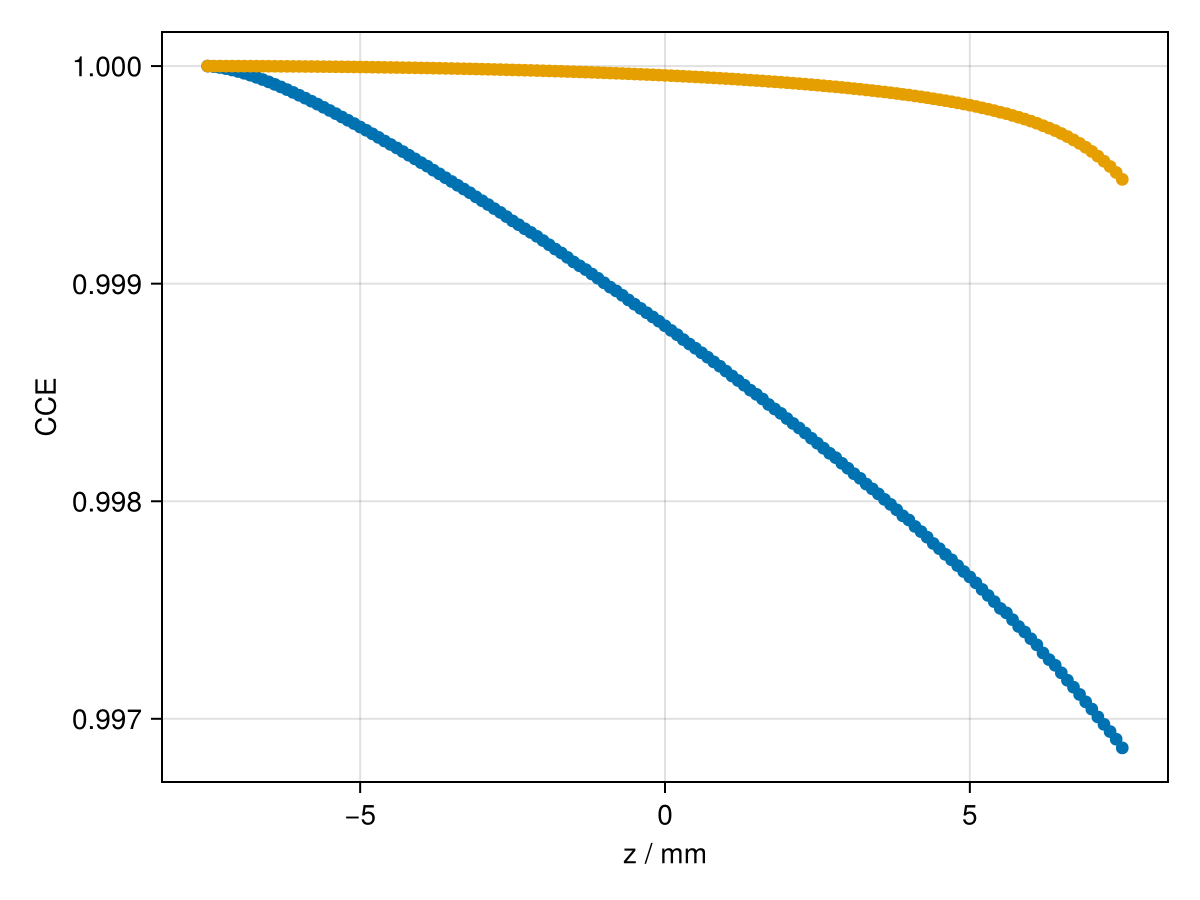

In [ ]:
#without electronics 
max_HV = maximum(getindex.(h_no_electronics, 1))
display(max_HV)
max_LV = maximum(getindex.(h_no_electronics, 2))#without electronics 

h_CCE_LV_noelectronics = getindex.(h_no_electronics, 2) / max_LV
h_CCE_HV_noelectronics = getindex.(h_no_electronics, 1) / max_HV

scatter(ustrip.(u"mm", zs),  h_CCE_LV_noelectronics, label = "LV", (axis = (xlabel = "z / mm", ylabel = "CCE" )))
scatter!(ustrip.(u"mm", zs), h_CCE_HV_noelectronics, label = "HV")


# scatter(ustrip.(u"mm", zs),  getindex.(h_no_electronics, 2), label = "LV", (axis = (xlabel = "z / mm", ylabel = "CCE" )))
# scatter!(ustrip.(u"mm", zs), getindex.(h_no_electronics, 1), label = "HV")
current_figure()

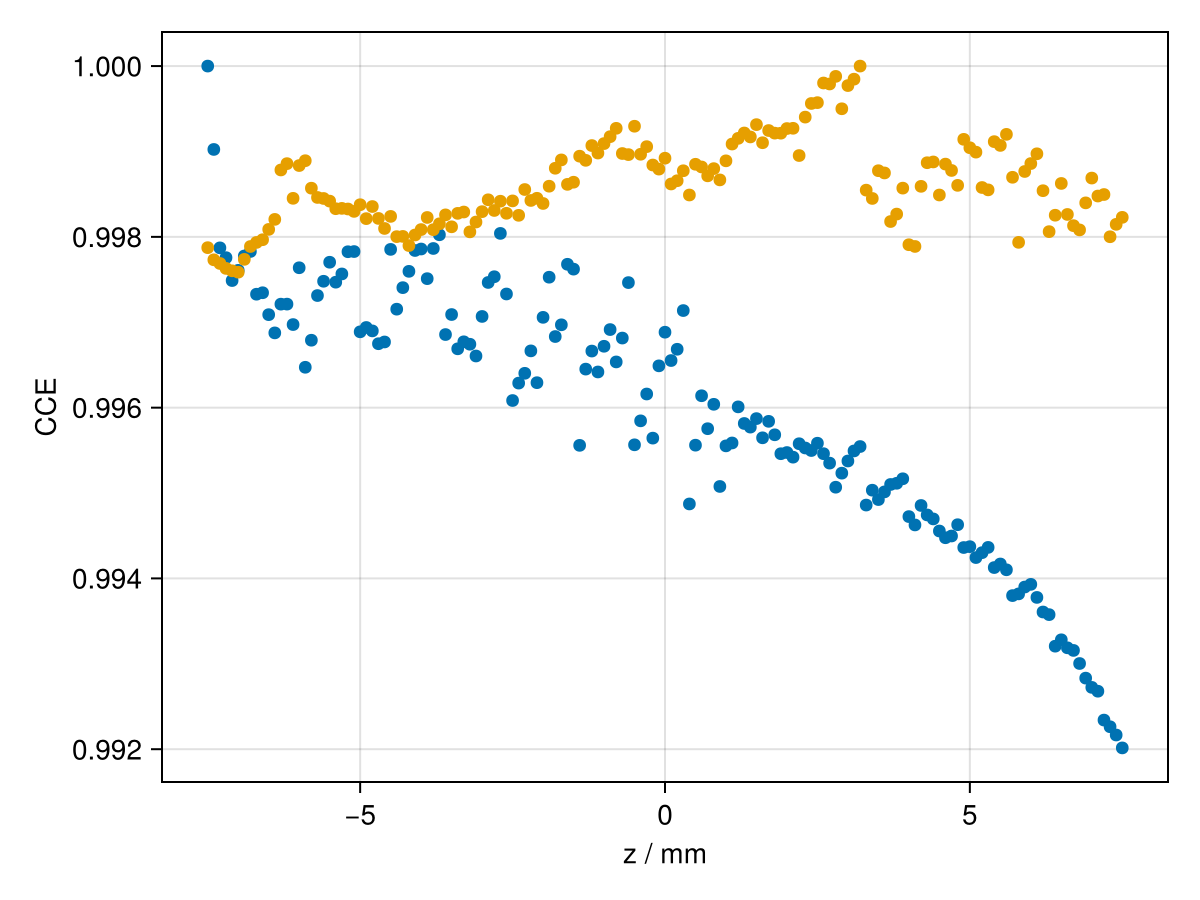

In [ ]:
#max_all = maximum(vcat(getindex.(h_result,1), getindex.(h_result,2)))
max_HV = maximum(getindex.(h_result, 1))
max_LV = maximum(getindex.(h_result, 2))
scatter(ustrip.(u"mm", zs), getindex.(h_result,2)/max_LV, label = "LV", (axis = (xlabel = "z / mm", ylabel = "CCE" )))
scatter!(ustrip.(u"mm", zs), getindex.(h_result,1)/max_HV, label = "HV")
current_figure()

Take binned mean across depths to eliminate sampling from electronics:

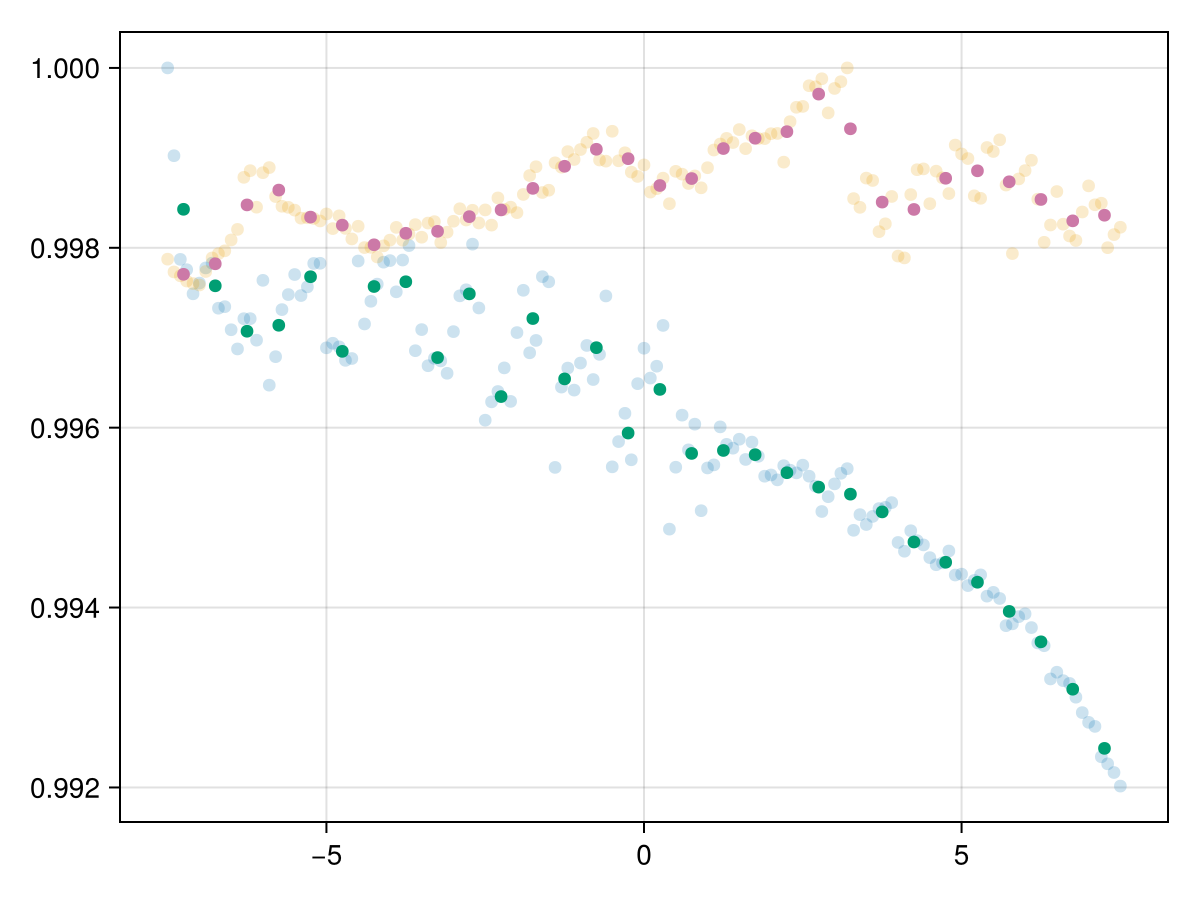

In [ ]:
z_mm = ustrip.(u"mm", zs)

h_CCE_LV = getindex.(h_result,2) ./ max_LV
h_CCE_HV = getindex.(h_result,1) ./ max_HV

using StatsBase

nbins = 30
edges = range(minimum(z_mm), maximum(z_mm), length=nbins+1)

sum_LV = zeros(nbins)
sum_HV = zeros(nbins)
counts = zeros(Int, nbins)

bin_ids = searchsortedlast.(Ref(edges), z_mm)

for i in eachindex(z_mm)
    b = bin_ids[i]
    if 1 ≤ b ≤ nbins
        sum_LV[b] += h_CCE_LV[i]
        sum_HV[b] += h_CCE_HV[i]
        counts[b] += 1
    end
end

h_mean_LV = sum_LV ./ counts
h_mean_HV = sum_HV ./ counts

bin_centers = (edges[1:end-1] .+ edges[2:end]) ./ 2


scatter(z_mm, h_CCE_LV, alpha=0.2, label="LV events")
scatter!(z_mm, h_CCE_HV, alpha=0.2, label="HV events")

plot!(bin_centers, h_mean_LV,  label="LV mean")
plot!(bin_centers, h_mean_HV,  label="HV mean")
current_figure()


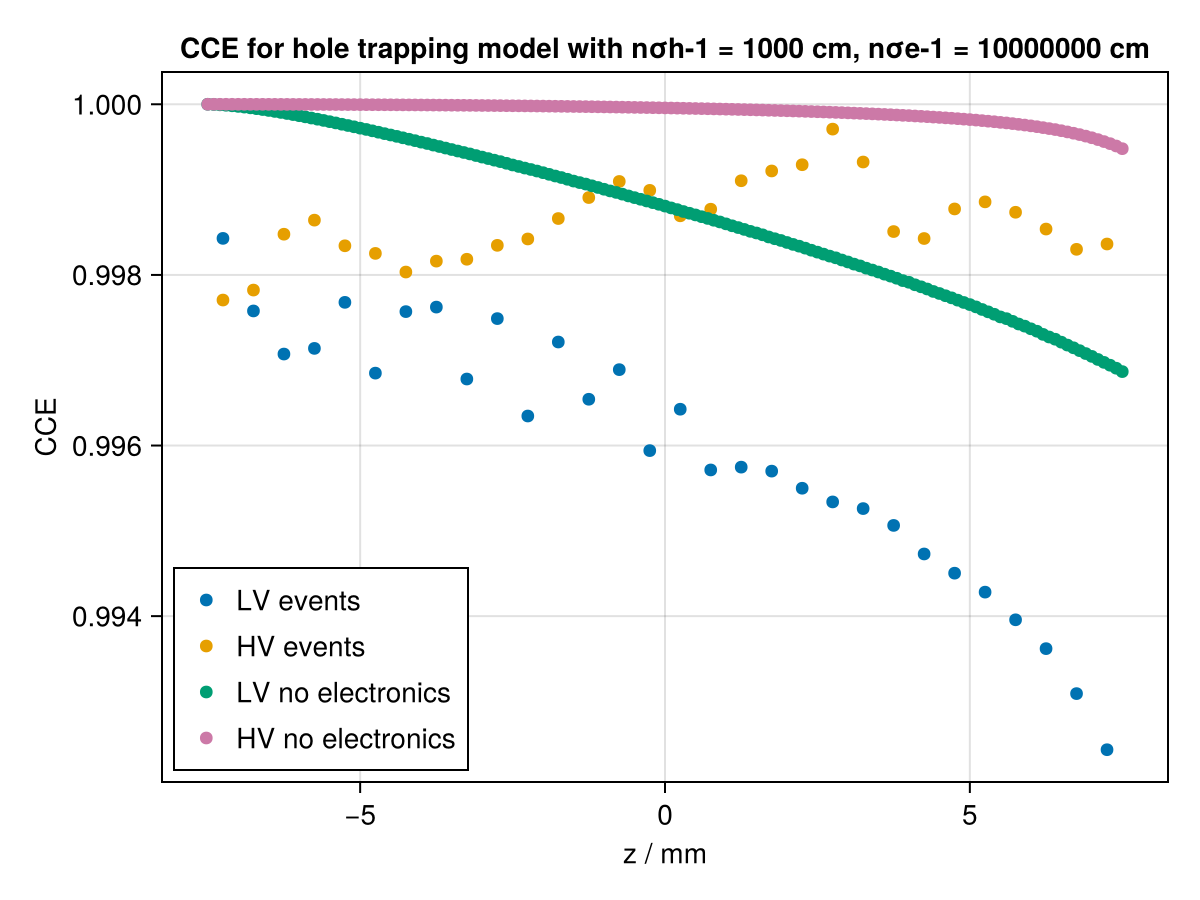

In [ ]:

fig = Figure()
ax = Axis(fig[1,1], xlabel="z / mm", ylabel="CCE", title ="CCE for hole trapping model with nσh-1 = 1000 cm, nσe-1 = 10000000 cm")

scatter!(ax, bin_centers, h_mean_LV,
     label="LV events")

scatter!(ax, bin_centers, h_mean_HV,
     label="HV events")

scatter!(ax, ustrip.(u"mm", zs), h_CCE_LV_noelectronics,
    label="LV no electronics")

scatter!(ax, ustrip.(u"mm", zs), h_CCE_HV_noelectronics,
    label="HV no electronics")

axislegend(ax, position = :lb)

fig

current_figure()

### Electron trapping on HV, LV strips 
let hoel trapping approach zero

In [ ]:
charge_drift_model = scale_to_temperature(ADL2016ChargeDriftModel{T}(), 89u"K")
sim.detector = SolidStateDetector(sim.detector, charge_drift_model);

# Add charge trapping model with parameters as wanted
parameters = Dict("parameters" => 
  Dict("nσe-1" => 1000u"cm", "nσh-1" => 10000000u"cm", "temperature" => 78u"K"))
sim.detector = SolidStateDetector(sim.detector, BoggsChargeTrappingModel{T}(parameters))


zs = (-7.5:0.1:7.5)u"mm"


n_threads = Threads.nthreads()
x = 0u"mm"/2
y = 0u"mm"/2
slow_threshold = 0.0u"keV"
energy_scale = 662.0u"keV"


prog = Progress(length(zs))
e_result = Vector{Tuple{typeof(1.0u"keV"), typeof(1.0u"keV")}}(undef, length(zs))
e_no_electronics= Vector{Tuple{typeof(1.0u"keV"), typeof(1.0u"keV")}}(undef, length(zs))
@onthreads 1:n_threads for (i,z) in workpart(collect(enumerate(zs)), 1:n_threads, Base.Threads.threadid())

    N = 100
    _e_result = Vector{Tuple{typeof(1.0u"keV"), typeof(1.0u"keV")}}(undef, N)
    _no_electronics = similar(_e_result)
    for j in 1:N
        evt = Event([CartesianPoint{T}(ustrip(u"m", x), ustrip(u"m", y), ustrip(u"m", z))], [energy_scale], 100, number_of_shells = 1, radius = [20f-6])
        simulate!(evt, sim, Δt = dt, diffusion = true, self_repulsion = true, max_nsteps = 1000)
        _no_electronics[j] = (maximum(-evt.waveforms[19].signal) * 2.95u"V", maximum(evt.waveforms[19 + n_strips].signal) * 2.95u"V")
        t, sampled = apply_electronics_fast(evt, S, strips = readout_strips, noise_lib = noise_lib)
        # println(sampled)
        slow_LV = filt(slow_filt, eachcol(sampled)[20 + n_strips])
        slow_HV = filt(slow_filt, eachcol(sampled)[20])
        E_HV = COSIDetectors.get_maximum(slow_HV * 1000u"keV", threshold = slow_threshold)
        E_LV = COSIDetectors.get_maximum(slow_LV * 1000u"keV", threshold = slow_threshold)
        _e_result[j] = (E_HV, E_LV)
        # display(_e_result[j])
    end
    e_result[i] = (mean(getindex.(_e_result, 1)), mean(getindex.(_e_result,2)))
    e_no_electronics[i] = (mean(getindex.(_no_electronics, 1)), mean(getindex.(_no_electronics, 2)))
    next!(prog)
end

In [ ]:
display(e_no_electronics)
display(e_result)

151-element Vector{Tuple{Quantity{Float64, 𝐋² 𝐌 𝐓⁻², Unitful.FreeUnits{(keV,), 𝐋² 𝐌 𝐓⁻², nothing}}, Quantity{Float64, 𝐋² 𝐌 𝐓⁻², Unitful.FreeUnits{(keV,), 𝐋² 𝐌 𝐓⁻², nothing}}}}:
 (659.9151183023131 keV, 661.7633772815549 keV)
 (659.9273283463527 keV, 661.7728725262139 keV)
 (659.9401596625796 keV, 661.7821324179716 keV)
 (659.9542404437069 keV, 661.7905414738417 keV)
 (659.9645679348562 keV, 661.7981966243723 keV)
 (659.9769836762823 keV, 661.8056656143428 keV)
 (659.9938693732305 keV, 661.8125845282219 keV)
 (660.0029651433932 keV, 661.8186070227247 keV)
 (660.0133481425786 keV, 661.824415007792 keV)
 (660.0280476524737 keV, 661.8301614125945 keV)
 ⋮
 (661.9145757213527 keV, 661.998903881938 keV)
 (661.9284084919504 keV, 661.9990649137449 keV)
 (661.9414135088643 keV, 661.9992106713345 keV)
 (661.9541546336096 keV, 661.99934704865 keV)
 (661.9647346471177 keV, 661.9994565583272 keV)
 (661.9747939619431 keV, 661.9995568202996 keV)
 (661.9833296629777 keV, 661.9996388366455 keV)
 (661.99

151-element Vector{Tuple{Quantity{Float64, 𝐋² 𝐌 𝐓⁻², Unitful.FreeUnits{(keV,), 𝐋² 𝐌 𝐓⁻², nothing}}, Quantity{Float64, 𝐋² 𝐌 𝐓⁻², Unitful.FreeUnits{(keV,), 𝐋² 𝐌 𝐓⁻², nothing}}}}:
 (663.5107029672213 keV, 667.5332749659652 keV)
 (663.5986481041017 keV, 666.7480778158955 keV)
 (663.389307199393 keV, 666.1847862742626 keV)
 (663.2583861712538 keV, 665.8908217065544 keV)
 (663.1779914870568 keV, 665.9015704164079 keV)
 (663.126659918351 keV, 665.8067163332688 keV)
 (663.4100577769962 keV, 666.0267406525586 keV)
 (663.4276956126973 keV, 665.8786213784675 keV)
 (663.679147583528 keV, 665.9807274467173 keV)
 (663.4852990992098 keV, 665.8316828488386 keV)
 ⋮
 (665.5162946948493 keV, 665.0673830962047 keV)
 (665.5209980049599 keV, 664.9436293649961 keV)
 (665.684582972136 keV, 664.8835333260497 keV)
 (665.7135978196637 keV, 664.7997442317611 keV)
 (665.7035075153951 keV, 664.8236533874573 keV)
 (665.7844096448913 keV, 664.6761039102889 keV)
 (665.8802326466645 keV, 664.6796592195623 keV)
 (665.61

661.9956860154351 keV

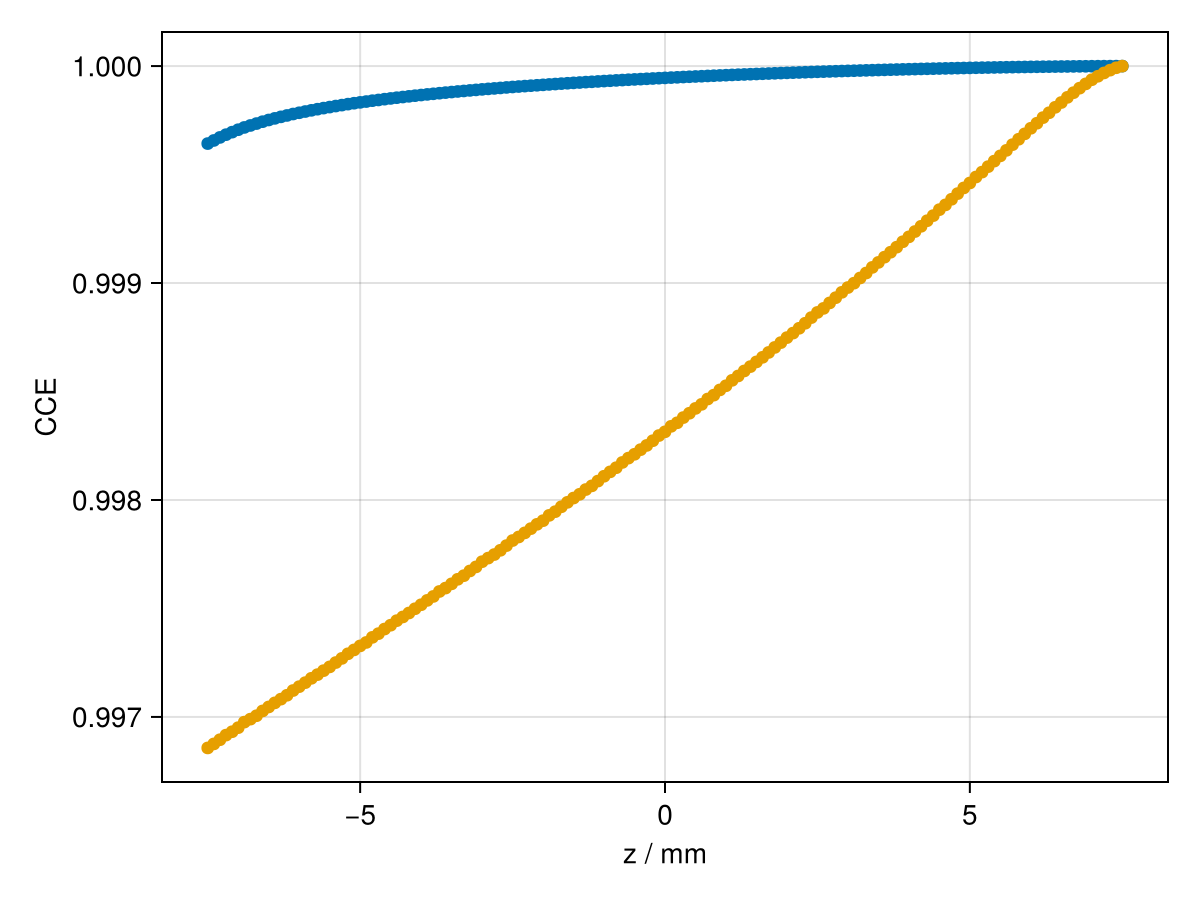

In [ ]:
#without electronics 

max_HV = maximum(getindex.(e_no_electronics, 1))
display(max_HV)
max_LV = maximum(getindex.(e_no_electronics, 2))#without electronics 

e_CCE_LV_noelectronics = getindex.(e_no_electronics, 2) / max_LV
e_CCE_HV_noelectronics = getindex.(e_no_electronics, 1) / max_HV

scatter(ustrip.(u"mm", zs),  e_CCE_LV_noelectronics, label = "LV", (axis = (xlabel = "z / mm", ylabel = "CCE" )))
scatter!(ustrip.(u"mm", zs), e_CCE_HV_noelectronics, label = "HV")


# scatter(ustrip.(u"mm", zs),  getindex.(h_no_electronics, 2), label = "LV", (axis = (xlabel = "z / mm", ylabel = "CCE" )))
# scatter!(ustrip.(u"mm", zs), getindex.(h_no_electronics, 1), label = "HV")
current_figure()

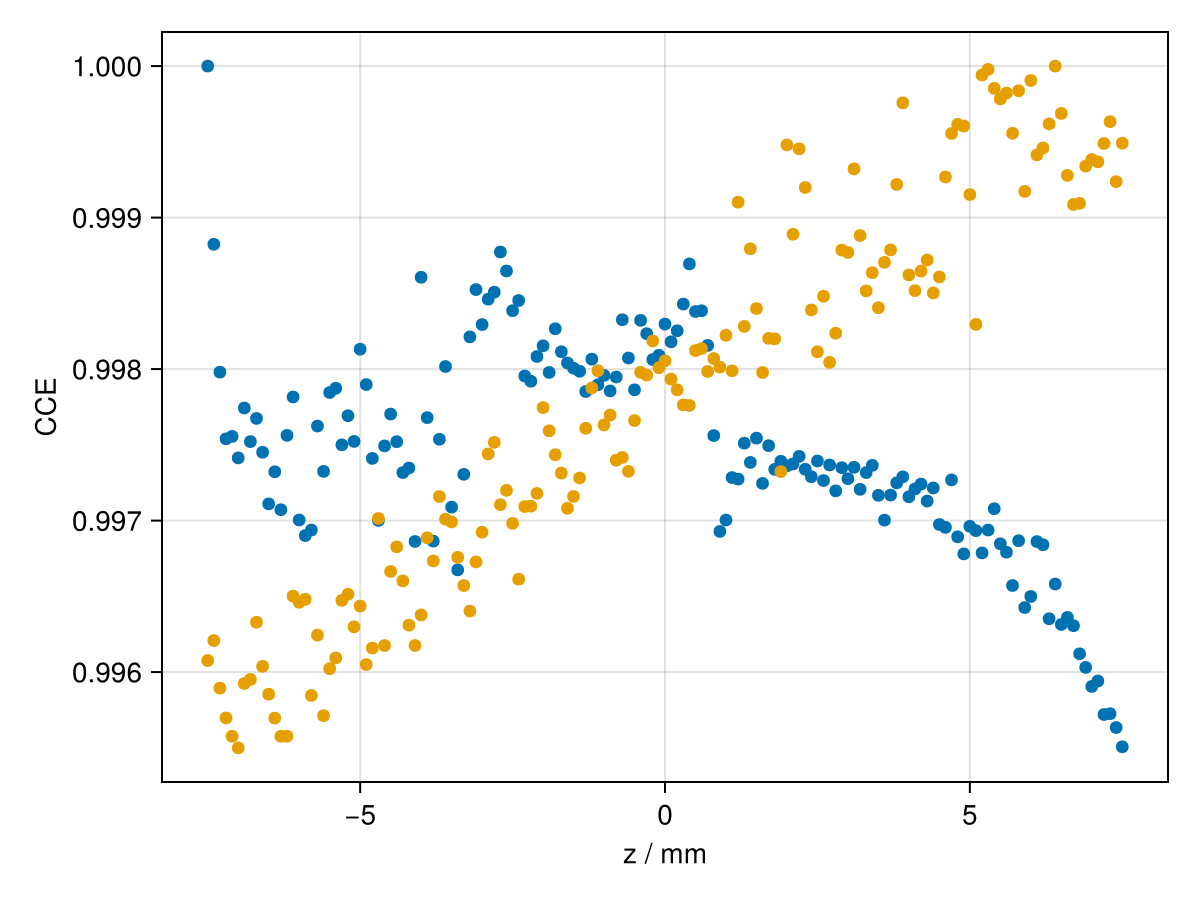

In [ ]:
#with electronics effects
max_HV = maximum(getindex.(e_result, 1))
max_LV = maximum(getindex.(e_result, 2))
scatter(ustrip.(u"mm", zs), getindex.(e_result,2)/max_LV, label = "LV", (axis = (xlabel = "z / mm", ylabel = "CCE" )))
scatter!(ustrip.(u"mm", zs), getindex.(e_result,1)/max_HV, label = "HV")
current_figure()

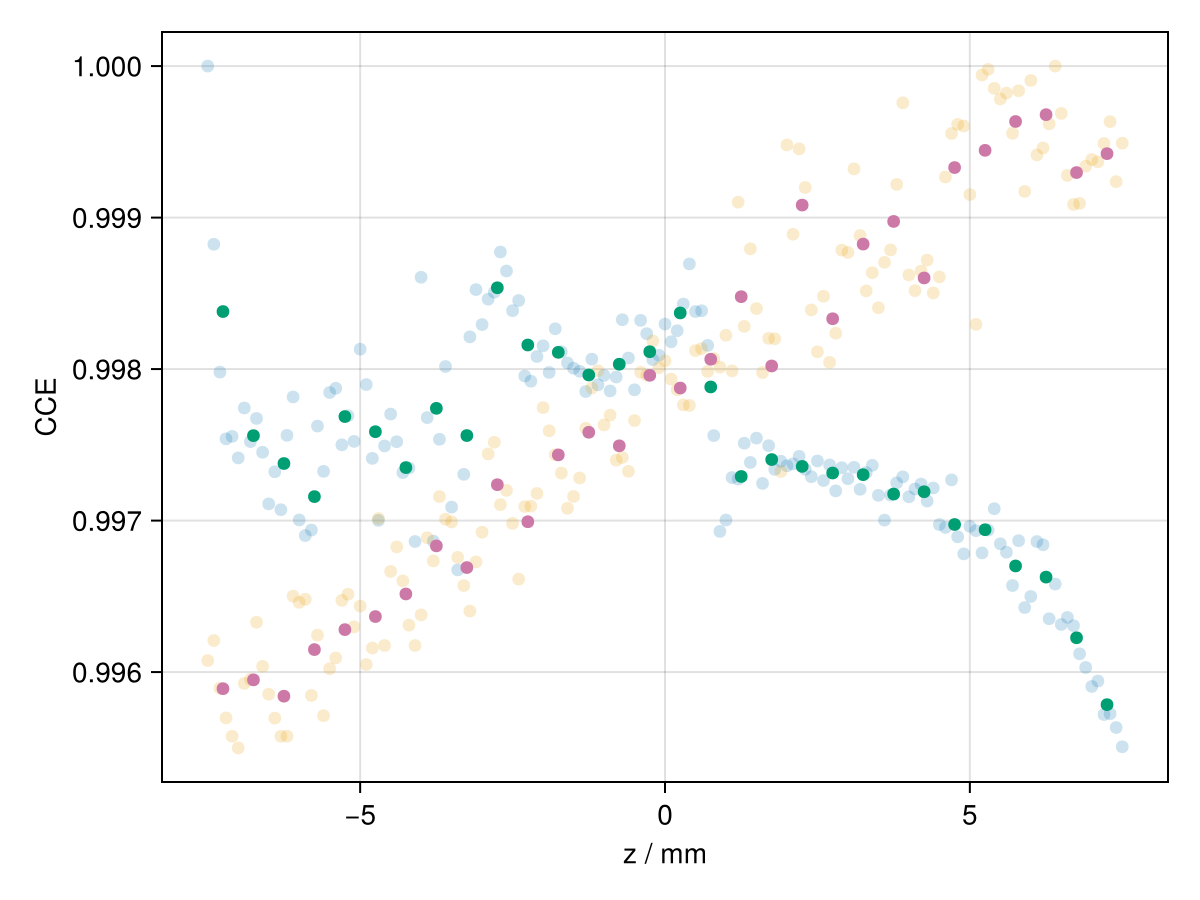

In [ ]:
z_mm = ustrip.(u"mm", zs)

e_CCE_LV = getindex.(e_result,2) ./ max_LV
e_CCE_HV = getindex.(e_result,1) ./ max_HV



using StatsBase

nbins = 30
edges = range(minimum(z_mm), maximum(z_mm), length=nbins+1)

sum_LV = zeros(nbins)
sum_HV = zeros(nbins)
counts = zeros(Int, nbins)

bin_ids = searchsortedlast.(Ref(edges), z_mm)

for i in eachindex(z_mm)
    b = bin_ids[i]
    if 1 ≤ b ≤ nbins
        sum_LV[b] += e_CCE_LV[i]
        sum_HV[b] += e_CCE_HV[i]
        counts[b] += 1
    end
end

e_mean_LV = (sum_LV ./ counts) 
e_mean_HV = (sum_HV ./ counts) 

bin_centers = (edges[1:end-1] .+ edges[2:end]) ./ 2


scatter(z_mm, e_CCE_LV, alpha=0.2, label="LV events", (axis = (xlabel = "z / mm", ylabel = "CCE" )))
scatter!(z_mm, e_CCE_HV, alpha=0.2, label="HV events")

plot!(bin_centers, e_mean_LV,  label="LV mean")
plot!(bin_centers, e_mean_HV,  label="HV mean")
current_figure()

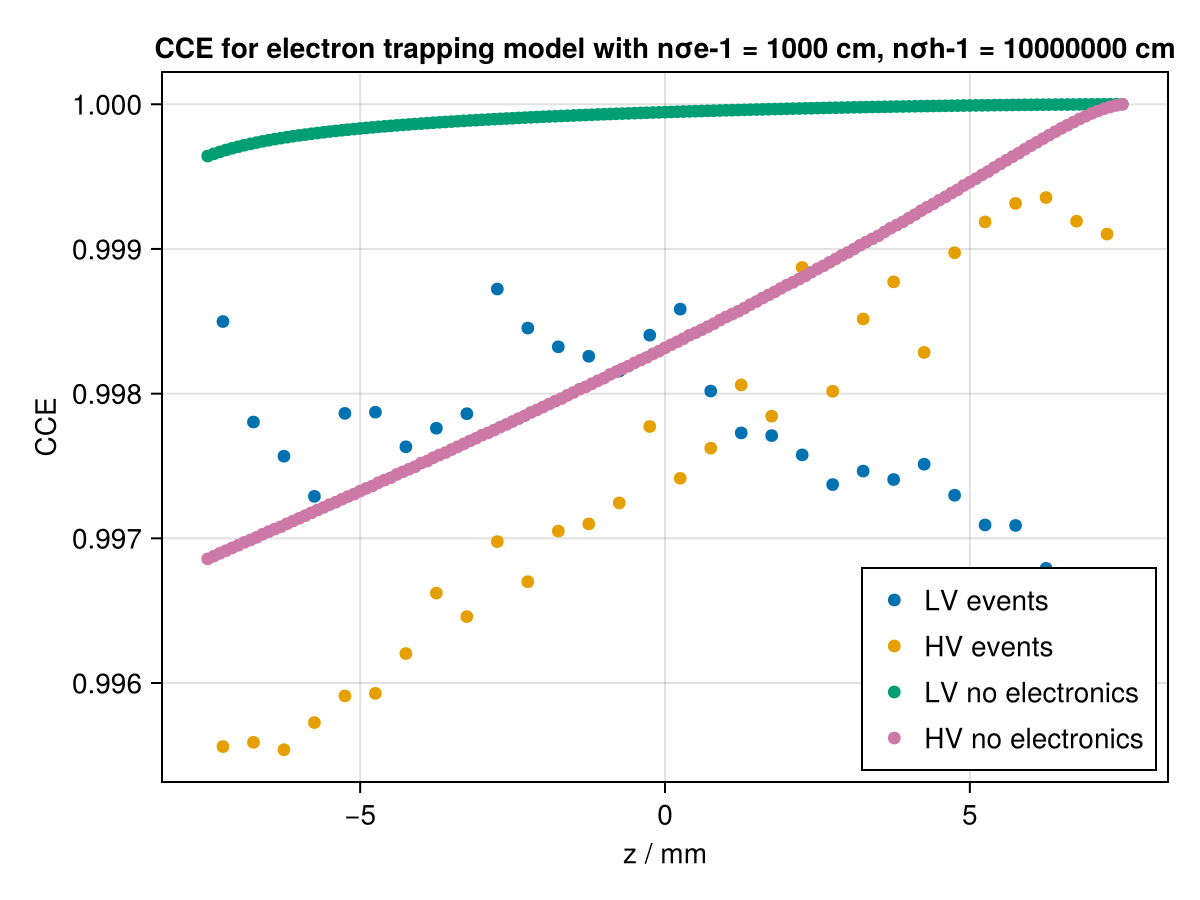

In [ ]:

fig = Figure()
ax = Axis(fig[1,1], xlabel="z / mm", ylabel="CCE", title ="CCE for electron trapping model with nσe-1 = 1000 cm, nσh-1 = 10000000 cm")

scatter!(ax, bin_centers, e_mean_LV,
     label="LV events")

scatter!(ax, bin_centers, e_mean_HV,
     label="HV events")

scatter!(ax, ustrip.(u"mm", zs), e_CCE_LV_noelectronics,
    label="LV no electronics")

scatter!(ax, ustrip.(u"mm", zs), e_CCE_HV_noelectronics,
    label="HV no electronics")

axislegend(ax, position = :rb)

fig

current_figure()

### For detector + electronic noise, multiply CCE for e and h on HV and LV strips to get combined CCE curves:

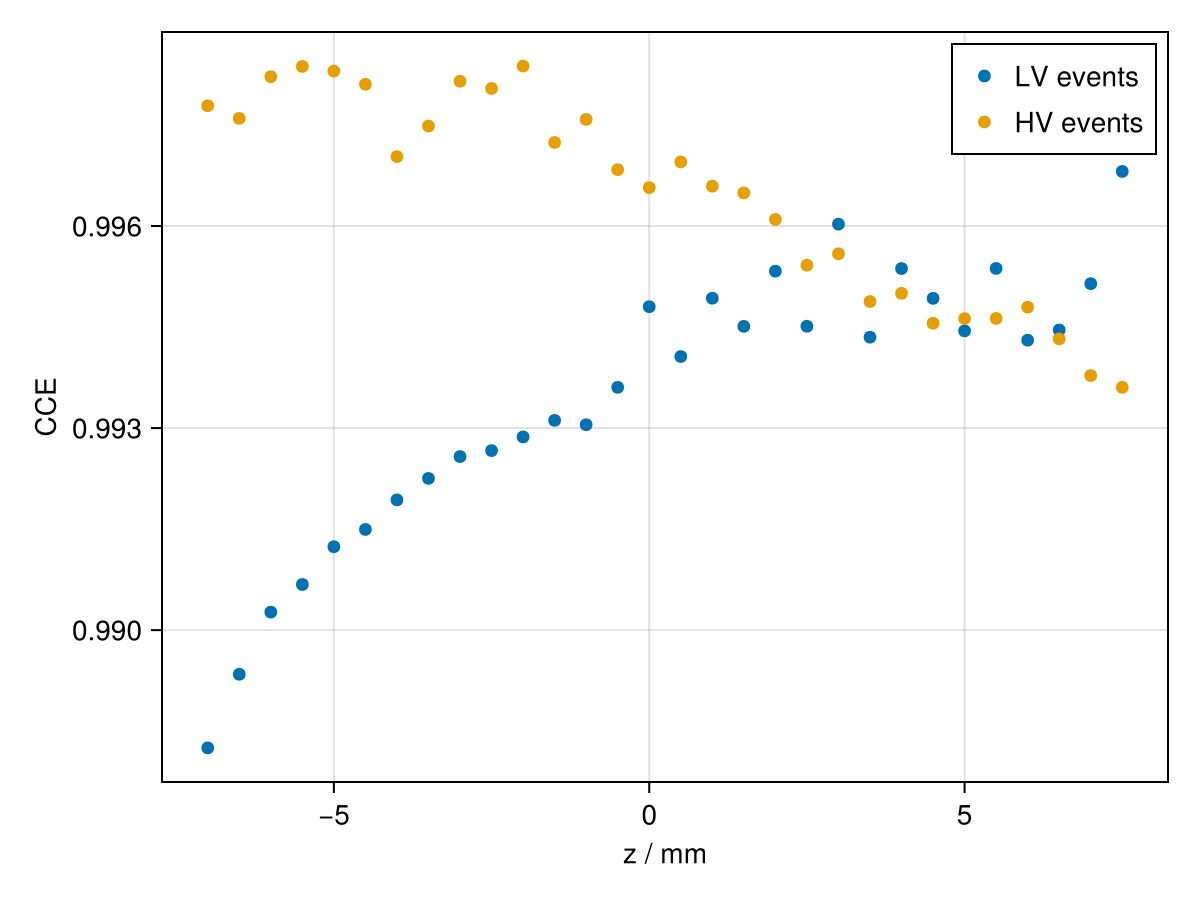

In [ ]:
# In these, b=electron trapping, c=hole trapping

#placeholder values
b=1
c=1

CCE_HV = (1. .- (b .* (1. .- e_mean_HV))) .*(1. .- (c .* (1. .- h_mean_HV)))
CCE_LV = (1. .- (b .* (1. .-e_mean_LV))) .*(1. .- (c .* ( 1. .-h_mean_LV)))


fig = Figure()
ax = Axis(fig[1,1], xlabel="z / mm", ylabel="CCE")

scatter!(ax, edges[end:-1:2], CCE_LV,  label="LV events")
scatter!(ax, edges[end:-1:2], CCE_HV, label="HV events")

axislegend(ax)

fig

### For detector w/o electronic noise, multiply CCEs for e and h to get overall CCE on LV and HV strips:

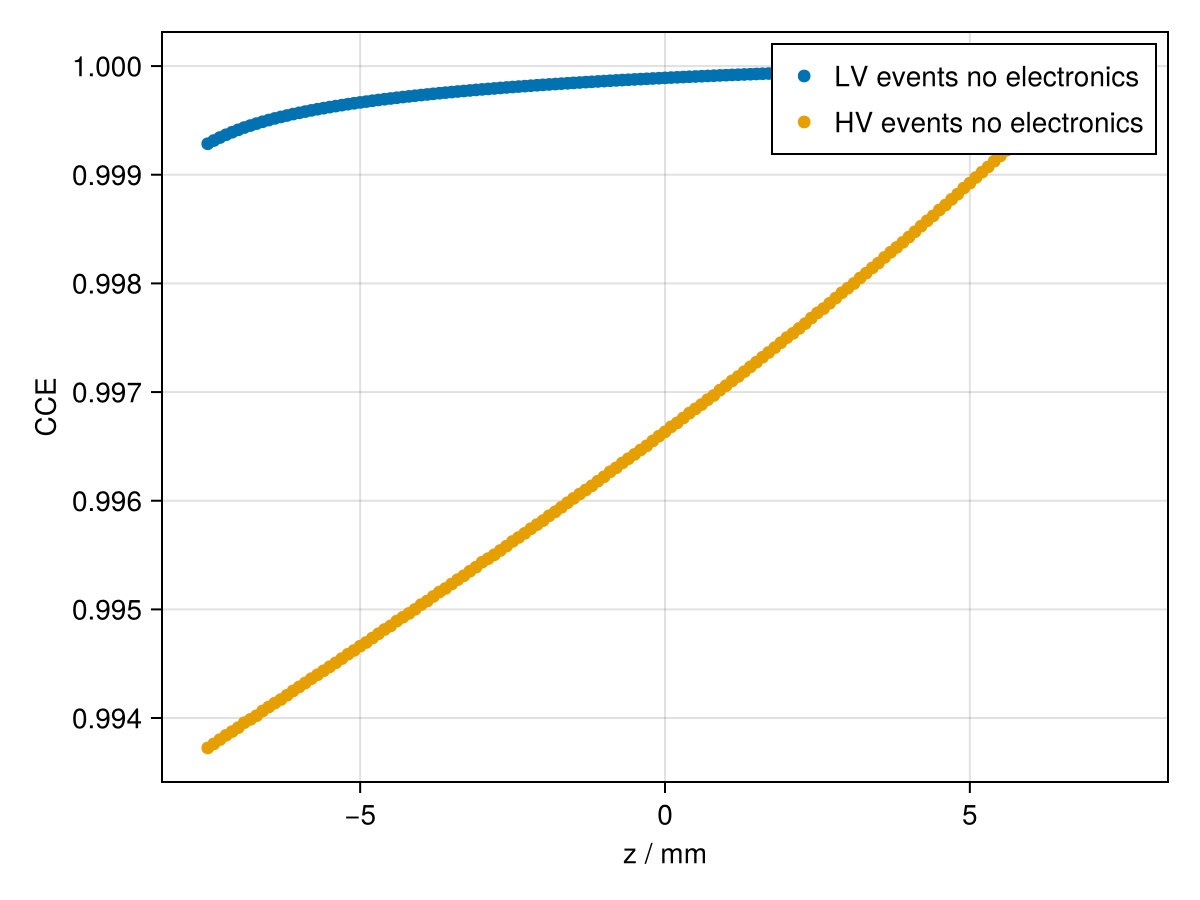

In [ ]:
# In these, b=electron trapping, c=hole trapping

#placeholder values
b=1
c=1

CCE_HV_noelectronics = (1. .- (b .* (1. .- e_CCE_HV_noelectronics))) .*(1. .- (c .* (1. .- h_CCE_HV_noelectronics)))
CCE_LV_noelectronics = (1. .- (b .* (1. .-e_CCE_LV_noelectronics))) .*(1. .- (c .* ( 1. .-h_CCE_LV_noelectronics)))




fig = Figure()
ax = Axis(fig[1,1], xlabel="z / mm", ylabel="CCE")

scatter!(ax, z_mm, CCE_LV_noelectronics, label="LV events no electronics")
scatter!(ax, z_mm, CCE_HV_noelectronics, label="HV events no electronics")

axislegend(ax)

fig




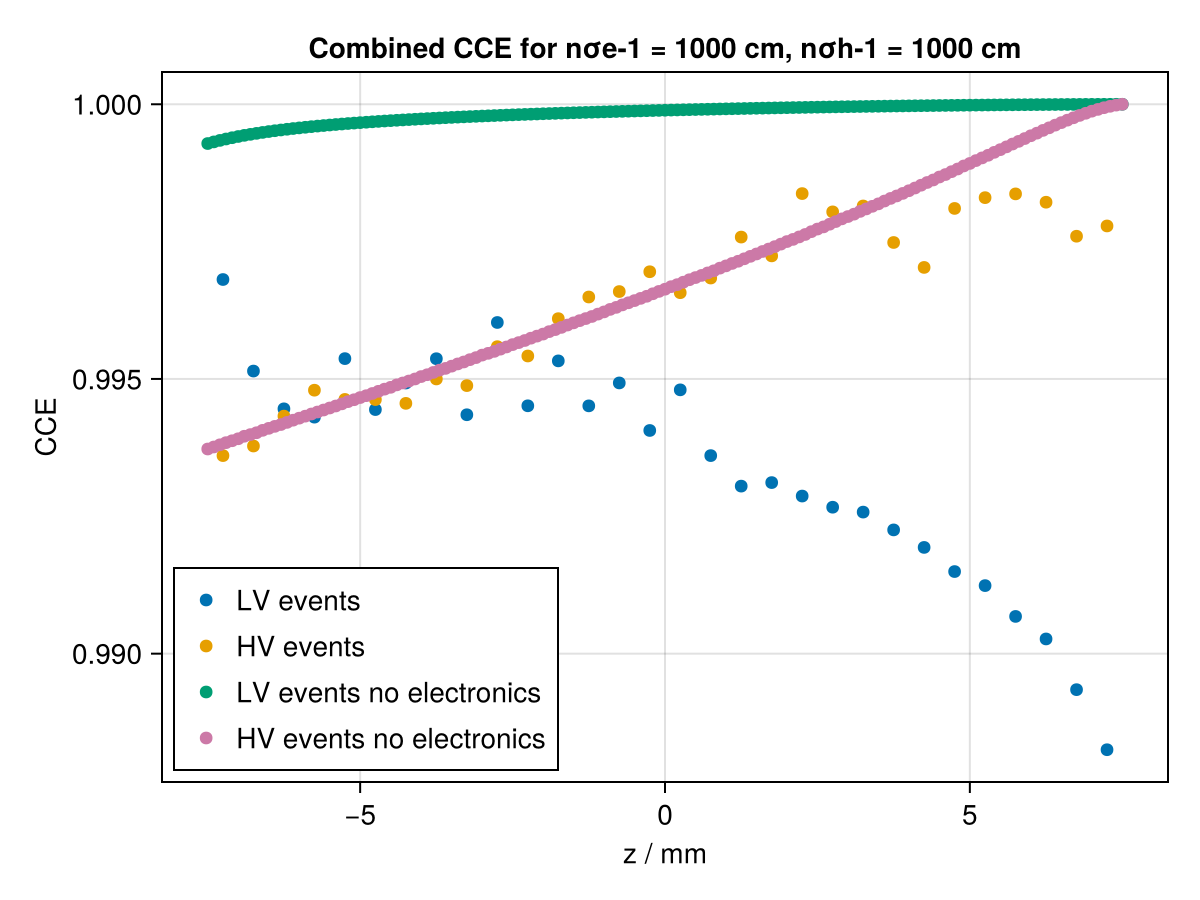

In [ ]:
fig = Figure()
ax = Axis(fig[1,1], xlabel="z / mm", ylabel="CCE", title ="Combined CCE for nσe-1 = 1000 cm, nσh-1 = 1000 cm")

scatter!(ax, bin_centers, CCE_LV,  label="LV events")
scatter!(ax, bin_centers, CCE_HV, label="HV events")

scatter!(ax, z_mm, CCE_LV_noelectronics, label="LV events no electronics")
scatter!(ax, z_mm, CCE_HV_noelectronics, label="HV events no electronics")

axislegend(ax, position = :lb)

fig


### Produce Cs-137 Events at different hole trapping densities

Start at nσh-1 = 2000 cm (no hole trapping) and hold electron trapping at nσe-1 = 2000 cm

In [ ]:
charge_drift_model = scale_to_temperature(ADL2016ChargeDriftModel{T}(), 89u"K")
sim.detector = SolidStateDetector(sim.detector, charge_drift_model);

# Add charge trapping model with parameters as wanted
parameters = Dict("parameters" => 
  Dict("nσe-1" => 2000u"cm", "nσh-1" => 2000u"cm", "temperature" => 78u"K"))
sim.detector = SolidStateDetector(sim.detector, BoggsChargeTrappingModel{T}(parameters))


zs = (-7.5:0.1:7.5)u"mm"


n_threads = Threads.nthreads()
x = 0u"mm"/2
y = 0u"mm"/2
slow_threshold = 0.0u"keV"
energy_scale = 661.7u"keV"


prog = Progress(length(zs))
energies_result = Vector{Tuple{typeof(1.0u"keV"), typeof(1.0u"keV")}}(undef, length(zs))
energies_no_electronics= Vector{Tuple{typeof(1.0u"keV"), typeof(1.0u"keV")}}(undef, length(zs))
@onthreads 1:n_threads for (i,z) in workpart(collect(enumerate(zs)), 1:n_threads, Base.Threads.threadid())

    N = 1000
    _energies_result = Vector{Tuple{typeof(1.0u"keV"), typeof(1.0u"keV")}}(undef, N)
    _no_electronics = similar(_energies_result)
    for j in 1:N
        evt = Event([CartesianPoint{T}(ustrip(u"m", x), ustrip(u"m", y), ustrip(u"m", z))], [energy_scale], 100, number_of_shells = 1, radius = [20f-6])
        simulate!(evt, sim, Δt = dt, diffusion = true, self_repulsion = true, max_nsteps = 1000)
        _no_electronics[j] = (maximum(-evt.waveforms[19].signal) * 2.95u"V", maximum(evt.waveforms[19 + n_strips].signal) * 2.95u"V")
        t, sampled = apply_electronics_fast(evt, S, strips = readout_strips, noise_lib = noise_lib)
        # println(sampled)
        slow_LV = filt(slow_filt, eachcol(sampled)[20 + n_strips])
        slow_HV = filt(slow_filt, eachcol(sampled)[20])
        E_HV = COSIDetectors.get_maximum(slow_HV * 1000u"keV", threshold = slow_threshold)
        E_LV = COSIDetectors.get_maximum(slow_LV * 1000u"keV", threshold = slow_threshold)
        _energies_result[j] = (E_HV, E_LV)
        # display(_e_result[j])
    end
    energies_result[i] = (mean(getindex.(_energies_result, 1)), mean(getindex.(_energies_result,2)))
    energies_no_electronics[i] = (mean(getindex.(_no_electronics, 1)), mean(getindex.(_no_electronics, 2)))
    next!(prog)
end

In [ ]:
using DelimitedFiles

# Define the range of values to sweep
noh_values = [10, 14, 20, 24, 30, 40, 50, 70, 100, 140, 200, 300, 500, 700, 1400, 2000]

# Setup invariant parts of the detector
charge_drift_model = scale_to_temperature(ADL2016ChargeDriftModel{T}(), 89u"K")

zs = (-7.5:0.1:7.5)u"mm"
n_threads = Threads.nthreads()
x = 0u"mm"/2
y = 0u"mm"/2
slow_threshold = 0.0u"keV"
energy_scale = 661.7u"keV"

# Outer loop across all nσh-1 values
for noh in noh_values
    println("\n--- Starting Simulation for nσh-1 = $noh u\"cm\" ---")
    
    # 1. Update the trapping model dynamically for this iteration
    sim.detector = SolidStateDetector(sim.detector, charge_drift_model)
    parameters = Dict("parameters" => 
      Dict("nσe-1" => 2000u"cm", "nσh-1" => noh * 1.0u"cm", "temperature" => 78u"K"))
    sim.detector = SolidStateDetector(sim.detector, BoggsChargeTrappingModel{T}(parameters))

    # 2. Reset containers for the current simulation run
    prog = Progress(length(zs))
    energies_result = Vector{Tuple{typeof(1.0u"keV"), typeof(1.0u"keV")}}(undef, length(zs))
    energies_no_electronics = Vector{Tuple{typeof(1.0u"keV"), typeof(1.0u"keV")}}(undef, length(zs))

    # 3. Parallelized simulation loop
    @onthreads 1:n_threads for (i,z) in workpart(collect(enumerate(zs)), 1:n_threads, Base.Threads.threadid())
        N = 1000
        _energies_result = Vector{Tuple{typeof(1.0u"keV"), typeof(1.0u"keV")}}(undef, N)
        _no_electronics = similar(_energies_result)
        for j in 1:N
            evt = Event([CartesianPoint{T}(ustrip(u"m", x), ustrip(u"m", y), ustrip(u"m", z))], [energy_scale], 100, number_of_shells = 1, radius = [20f-6])
            simulate!(evt, sim, Δt = dt, diffusion = true, self_repulsion = true, max_nsteps = 1000)
            _no_electronics[j] = (maximum(-evt.waveforms[19].signal) * 2.95u"V", maximum(evt.waveforms[19 + n_strips].signal) * 2.95u"V")
            t, sampled = apply_electronics_fast(evt, S, strips = readout_strips, noise_lib = noise_lib)
            
            slow_LV = filt(slow_filt, eachcol(sampled)[20 + n_strips])
            slow_HV = filt(slow_filt, eachcol(sampled)[20])
            E_HV = COSIDetectors.get_maximum(slow_HV * 1000u"keV", threshold = slow_threshold)
            E_LV = COSIDetectors.get_maximum(slow_LV * 1000u"keV", threshold = slow_threshold)
            _energies_result[j] = (E_HV, E_LV)
        end
        energies_result[i] = (mean(getindex.(_energies_result, 1)), mean(getindex.(_energies_result,2)))
        energies_no_electronics[i] = (mean(getindex.(_no_electronics, 1)), mean(getindex.(_no_electronics, 2)))
        next!(prog)
    end

    # 4. Extract data and export to uniquely named CSV
    energies_HV = ustrip.(u"keV", getindex.(energies_result, 1))
    energies_LV = ustrip.(u"keV", getindex.(energies_result, 2))
    data_to_save = hcat(energies_HV, energies_LV)
    
    filename = "simulated_energies_noh_$(noh).csv"
    writedlm(filename, data_to_save, ',')
    println("Saved results to $filename")
end

In [ ]:
using DelimitedFiles
using Statistics
using ProgressMeter
using Base.Threads

function run_depth_chunk!(final_matrix, global_start_idx, sim, slow_filt, target_z, events_to_simulate, noh, x, y, slow_threshold, energy_scale, n_strips, dt)
    n_threads = Threads.nthreads()
    
    # Divide the local event quota for this depth across available threads
    base_chunk = div(events_to_simulate, n_threads)
    chunks = [ (tid == n_threads) ? (events_to_simulate - base_chunk * (n_threads - 1)) : base_chunk for tid in 1:n_threads ]
    
    # Calculate starting indices for each thread partition within the global matrix block
    thread_offsets = cumsum([0; chunks[1:end-1]])

    Threads.@threads for tid in 1:n_threads
        my_chunk_len = chunks[tid]
        my_offset = global_start_idx + thread_offsets[tid]
        
        T = typeof(ustrip(target_z))
        pos = [CartesianPoint{T}(ustrip(u"m", x), ustrip(u"m", y), ustrip(u"m", target_z))]
        evt = SolidStateDetectors.Event(pos, [energy_scale], 100, number_of_shells = 1, radius = [20f-6])
        
        for idx in 1:my_chunk_len
            simulate!(evt, sim, Δt = dt, diffusion = true, self_repulsion = true, max_nsteps = 1000)
            
            t, sampled = apply_electronics_fast(evt, S, strips = readout_strips, noise_lib = noise_lib)
            
            # 1. Raw (no electronics) amplitude of strip 19 from the SSD waveforms, as in the loops above
            v_hv = ustrip(u"keV", maximum(-evt.waveforms[19].signal) * 2.95u"V")
            v_lv = ustrip(u"keV", maximum(evt.waveforms[19 + n_strips].signal) * 2.95u"V")
            
            # 2. Electronics filtering runs on readout channel 20
            @views slow_LV = filt(slow_filt, sampled[:, 20 + n_strips])
            @views slow_HV = filt(slow_filt, sampled[:, 20])
            
            # 3. Apply calibrated amplifier scaling matrix
            E_HV = COSIDetectors.get_maximum(slow_HV * 993.54u"keV", threshold = slow_threshold)
            E_LV = COSIDetectors.get_maximum(slow_LV * 993.54u"keV", threshold = slow_threshold)
            
            # 4. Write data directly into the master matrix mapping space
            write_row = my_offset + idx
            final_matrix[write_row, 1] = ustrip(u"keV", E_HV)
            final_matrix[write_row, 2] = ustrip(u"keV", E_LV)
            final_matrix[write_row, 3] = ustrip(v_hv)
            final_matrix[write_row, 4] = ustrip(v_lv)
            final_matrix[write_row, 5] = ustrip(u"mm", target_z) # Save the depth footprint!
        end
    end
end

Now plot the events in a hist 

In [ ]:

using ProgressMeter


total_combined_events = 10_000
noh_list = [10, 14, 20, 24, 30, 40, 50, 70, 100, 140, 200, 300, 500, 700, 1400, 2000] #[662, 492, 575, 585, 616, 600, 611, 627]  # List of noh values to sweep over

# Generate depth range from -7.5mm to +7.5mm in 0.1mm increments (151 depths)
z_depths = collect(-7.5u"mm":0.1u"mm":7.5u"mm")
num_depths = length(z_depths)

# Base quota allocations per depth layer step
events_per_depth = div(total_combined_events, num_depths)

x = 0u"mm"/2
y = 0u"mm"/2
slow_threshold = 0.0u"keV"
energy_scale = 661.7u"keV"

# Setup base charge drift model once outside the outer loop
charge_drift_model = scale_to_temperature(ADL2016ChargeDriftModel{T}(), 89u"K")
sim.detector = SolidStateDetector(sim.detector, charge_drift_model)

# --------------------------------------------------
# Outer loop iterating over each noh parameter value
# --------------------------------------------------
for noh in noh_list
    println("\n==================================================")
    println("Running simulation for noh = $noh")
    println("==================================================")

    # 1. Update trapping model with current noh parameter
    parameters = Dict("parameters" => Dict("nσe-1" => 1000u"cm", "nσh-1" => noh * 1.0u"cm", "temperature" => 78u"K"))
    sim.detector = SolidStateDetector(sim.detector, BoggsChargeTrappingModel{T}(parameters))

    # 2. Re-allocate matrix and reset global row pointer for each iteration
    master_matrix = Matrix{Float64}(undef, total_combined_events, 5)
    global_row_pointer = 0

    # 3. Sequential depth sweep
    @showprogress 1 "Sweeping depth range (noh=$noh): " for (step_idx, current_z) in enumerate(z_depths)
        local_quota = (step_idx == num_depths) ? (total_combined_events - global_row_pointer) : events_per_depth
        
        if local_quota <= 0; continue; end

        run_depth_chunk!(
            master_matrix, global_row_pointer, sim, slow_filt, current_z, 
            local_quota, noh, x, y, slow_threshold, energy_scale, n_strips, dt
        )
        
        global_row_pointer += local_quota
    end

    # 4. Export results into a dedicated CSV file for current noh
    filename = "simulated_events_noh_$(noh)_combined_depths_10k.csv"
    header = "E_HV_keV,E_LV_keV,E_no_elec_HV_keV,E_no_elec_LV_keV,z_depth_mm\n"

    open(filename, "w") do io
        write(io, header)
        writedlm(io, master_matrix, ',')
    end

    println("Exported $(global_row_pointer) events to: $filename")
end

println("\nAll simulations completed successfully!")

In [ ]:
# # ----------------------------
# # 1. Convert to plain numbers
# # ----------------------------
# energy_keV = ustrip.(u"keV", getindex.(energies_result,2))

# # ----------------------------
# # 2. Select fit window
# # ----------------------------
# fit_min = 660
# fit_max = 663

# fit_energies = energy_keV[(energy_keV .>= fit_min) .&
#                           (energy_keV .<= fit_max)]

# # ----------------------------
# # 3. Histogram (Makie style)
# # ----------------------------
# nbins = 35

# hist = fit(Histogram, fit_energies, nbins=nbins)

# edges = hist.edges[1]
# counts = hist.weights
# centers = (edges[1:end-1] .+ edges[2:end]) ./ 2

# # ----------------------------
# # 4. Gaussian model
# # ----------------------------
# gaussian(x, p) = p[1] .* exp.(-(x .- p[2]).^2 ./ (2p[3]^2))

# A0 = maximum(counts)
# μ0 = mean(fit_energies)
# σ0 = std(fit_energies)

# p0 = [A0, μ0, σ0]

# fit_result = curve_fit(gaussian, centers, counts, p0)
# A_fit, μ_fit, σ_fit = coef(fit_result)

# # ----------------------------
# # 5. Histogram-based FWHM
# # ----------------------------
# half_max = maximum(counts) / 2

# idx = findall(counts .>= half_max)

# fwhm_hist = centers[last(idx)] - centers[first(idx)]

# # ----------------------------
# # 6. Plot (Makie)
# # ----------------------------
# fig = Figure(size = (800, 500))
# ax = Axis(fig[1, 1],
#     xlabel = "Energy (keV)",
#     ylabel = "Counts",
#     title = "Energy Spectrum + Gaussian Fit"
# )

# # histogram bars
# barplot!(ax, centers, counts,
#     width = diff(edges),
#     color = :skyblue,
#     label = "Histogram"
# )

# # # fit curve
# # xfit = range(fit_min, fit_max, length=1000)
# # lines!(ax, xfit, gaussian(xfit, coef(fit_result)),
# #     color = :red,
# #     linewidth = 3,
# #     label = "Gaussian fit"
# # )

# # # half max line
# # hlines!(ax, [half_max], linestyle = :dash, color = :black)

# # annotation
# text!(ax,
#     "μ = $(round(μ_fit, digits=2)) keV\n" *
#     "FWHM = $(round(fwhm_hist, digits=2)) keV",
#     position = (fit_min , maximum(counts)),
#     align = (:left, :center)
# )

# axislegend(ax)

# fig

In [18]:
print(getindex.(energies_no_electronics,2))

Quantity{Float64, 𝐋² 𝐌 𝐓⁻², Unitful.FreeUnits{(keV,), 𝐋² 𝐌 𝐓⁻², nothing}}[661.5811852742887 keV, 661.5851088086965 keV, 661.5883474825029 keV, 661.5907711172061 keV, 661.5926907555414 keV, 661.5938228711248 keV, 661.5945817050174 keV, 661.5948308844937 keV, 661.5946205005856 keV, 661.5939738398093 keV, 661.59290533178 keV, 661.5917879267862 keV, 661.5901554209922 keV, 661.5881636580699 keV, 661.5862408393562 keV, 661.5838366845436 keV, 661.58126628129 keV, 661.5785357563846 keV, 661.5757292834921 keV, 661.5723724936265 keV, 661.5694172326229 keV, 661.5660800860275 keV, 661.562497761908 keV, 661.5589090803749 keV, 661.5551876804055 keV, 661.5513813437383 keV, 661.5474360270873 keV, 661.5433298624508 keV, 661.5392458428668 keV, 661.5348704064938 keV, 661.5307306033459 keV, 661.5263026173114 keV, 661.5221367104862 keV, 661.5173117220837 keV, 661.5130603361798 keV, 661.5085317689748 keV, 661.5036616235583 keV, 661.4992181565966 keV, 661.4941304600226 keV, 661.4889742475641 keV, 661.4837815